### Lab 08: KNN CLASSIFIER

### **Student Information**

- **Name:** Abdullah Farooq
- **Roll_no:** 24F-AI-050

#### Lab Tasks:

- Load a dataset (e.g., Iris, Breast Cancer dataset).
- Apply data preprocessing (handle missing values, encode categorical data).
- Split the dataset into training and testing sets.
- Train a KNN classifier with different values of K (e.g., 3, 5, 7).
- Make predictions on the test set.
- Evaluate performance using accuracy, precision, recall, and F1-score.
- Test how accuracy changes with different values of K.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix, 
    classification_report
)

# Set standard plotting style
sns.set_theme(style="whitegrid")

In [6]:
plt.rcParams['figure.figsize'] = [4.4, 3.1]

plt.rcParams['figure.autolayout'] = True

In [2]:
# Task 1: Load Dataset

# Using the Breast Cancer dataset from sklearn.datasets
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
# Task 2: Data Preprocessing

# Handling missing values (if any) and encode categorical data
print(f"Missing values count: {df.isnull().sum().sum()}")

# Separate features and target labels
X = df.drop(columns=['target'])
y = df['target']

Missing values count: 0


In [4]:
# Task 3: Train-Test Split

# Splitting the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Scaling features because KNN relies on Euclidean/Manhattan distance metrics
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
# Task 4 & 5: Train KNN with Different Values of K & Make Predictions

# Training a KNN classifier with different values of K (e.g., 3, 5, 7)
k_values = [3, 5, 7]
models = {}
predictions = {}

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    
    models[k] = knn
    predictions[k] = y_pred

Evaluation Metrics for K = 5:
Accuracy:  0.9474
Precision: 0.9577
Recall:    0.9577
F1-Score:  0.9577

Classification Report (K = 5):

              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        43
      benign       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



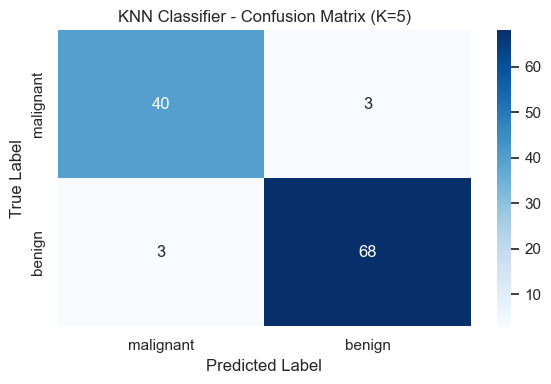

In [7]:
# Task 6: Evaluate Performance (Using K = 5 as primary example)

print("Evaluation Metrics for K = 5:")
y_pred_5 = predictions[5]

accuracy = accuracy_score(y_test, y_pred_5)
precision = precision_score(y_test, y_pred_5)
recall = recall_score(y_test, y_pred_5)
f1 = f1_score(y_test, y_pred_5)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}\n")

print("Classification Report (K = 5):\n")
print(classification_report(y_test, y_pred_5, target_names=data.target_names))

# Visualizing Confusion Matrix for K = 5
cm = confusion_matrix(y_test, y_pred_5)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=data.target_names, 
    yticklabels=data.target_names
)
plt.title("KNN Classifier - Confusion Matrix (K=5)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Accuracy for K = 3: 0.9474
Accuracy for K = 5: 0.9474
Accuracy for K = 7: 0.9474


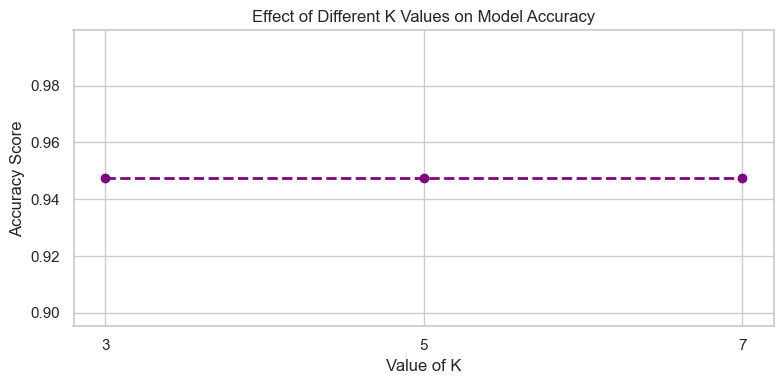

In [8]:
# Task 7: Test How Accuracy Changes with Different Values of K

accuracies = []

for k in k_values:
    acc = accuracy_score(y_test, predictions[k])
    accuracies.append(acc)
    print(f"Accuracy for K = {k}: {acc:.4f}")

# Plotting K vs Accuracy
plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, marker='o', color='purple', linestyle='--', linewidth=2)
plt.title("Effect of Different K Values on Model Accuracy")
plt.xlabel("Value of K")
plt.ylabel("Accuracy Score")
plt.xticks(k_values)
plt.show()